<a href="https://colab.research.google.com/github/Dani-Mol/InteligenciaArtificial/blob/main/clase_22_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clase 22-09


## Sección 1: Exploración y Filtrado de Datos

En esta sección aprenderemos a manejar bases de datos utilizando **Pandas** y **NumPy**, y a visualizarlas usando **Seaborn** y **Matplotlib**. Además, prepararemos los datos para que nuestro modelo (un Perceptrón Simple) pueda procesarlos.

Primero, importamos las herramientas requeridas para la práctica:

In [ ]:
# ==========================================
# IMPORTACIÓN DE BIBLIOTECAS
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# PyTorch: Framework de Deep Learning para construcción de grafos computacionales y tensores
import torch
import torch.nn as nn
import torch.optim as optim

### 1.1 Carga y Exploración del Dataset
Siguiendo las instrucciones, cargaremos el dataset `load_wine` de `sklearn.datasets` en un DataFrame de Pandas. Este dataset contiene resultados de un análisis químico de vinos cultivados en la misma región pero derivados de tres cultivares distintos.

In [ ]:
# Cargamos el dataset 'wine'. Scikit-learn devuelve un objeto tipo 'Bunch' (similar a un diccionario)
wine_data = load_wine()

# Construimos el DataFrame de Pandas.
# 'data' contiene la matriz de características y 'feature_names' los nombres de las columnas.
df_wine = pd.DataFrame(data=wine_data.data, columns=wine_data.feature_names)

# Añadimos la columna objetivo (target), que indica la clase de vino (0, 1 o 2)
df_wine['target'] = wine_data.target

# Visualizamos las primeras 5 filas para entender la estructura de los datos
display(df_wine.head())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


### 1.2 Filtrado para Clasificación Binaria
El Perceptrón Simple original está diseñado para **clasificación binaria**. Por lo tanto, debemos filtrar el DataFrame para conservar únicamente dos clases (clase 0 y clase 1), eliminando la tercera.

In [ ]:
# Usamos indexación booleana en Pandas.
# Filtramos las filas donde la columna 'target' sea menor a 2 (es decir, solo 0 y 1)
df_binario_0 = df_wine[df_wine['target'] < 2].copy()

# Tambien podemos quedarnos con la clase 0 y 2
df_binario_1 = df_wine[df_wine['target'] != 1].copy()

display(df_binario_0)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125,12.07,2.16,2.17,21.0,85.0,2.60,2.65,0.37,1.35,2.76,0.86,3.28,378.0,1
126,12.43,1.53,2.29,21.5,86.0,2.74,3.15,0.39,1.77,3.94,0.69,2.84,352.0,1
127,11.79,2.13,2.78,28.5,92.0,2.13,2.24,0.58,1.76,3.00,0.97,2.44,466.0,1
128,12.37,1.63,2.30,24.5,88.0,2.22,2.45,0.40,1.90,2.12,0.89,2.78,342.0,1


In [ ]:
display(df_binario_1)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


In [ ]:
# Reiniciamos el índice del DataFrame para mantener el orden secuencial tras eliminar filas
df_binario_0.reset_index(drop=True, inplace=True)

print(f"Dimensiones del dataset original: {df_wine.shape}")
print(f"Dimensiones tras filtrar la clase 2: {df_binario_0.shape}")

Dimensiones del dataset original: (178, 14)
Dimensiones tras filtrar la clase 2: (130, 14)


### 1.3 Visualización de Características
Generaremos un mínimo de dos gráficos de dispersión combinando diferentes pares de características[cite: 1]. Esto nos ayudará a inspeccionar visualmente qué variables son **linealmente separables**, un requisito matemático crucial para que un Perceptrón Simple sin capas ocultas converja adecuadamente. Usaremos paletas de colores distintas para diferenciar cada clase de vino[cite: 1].

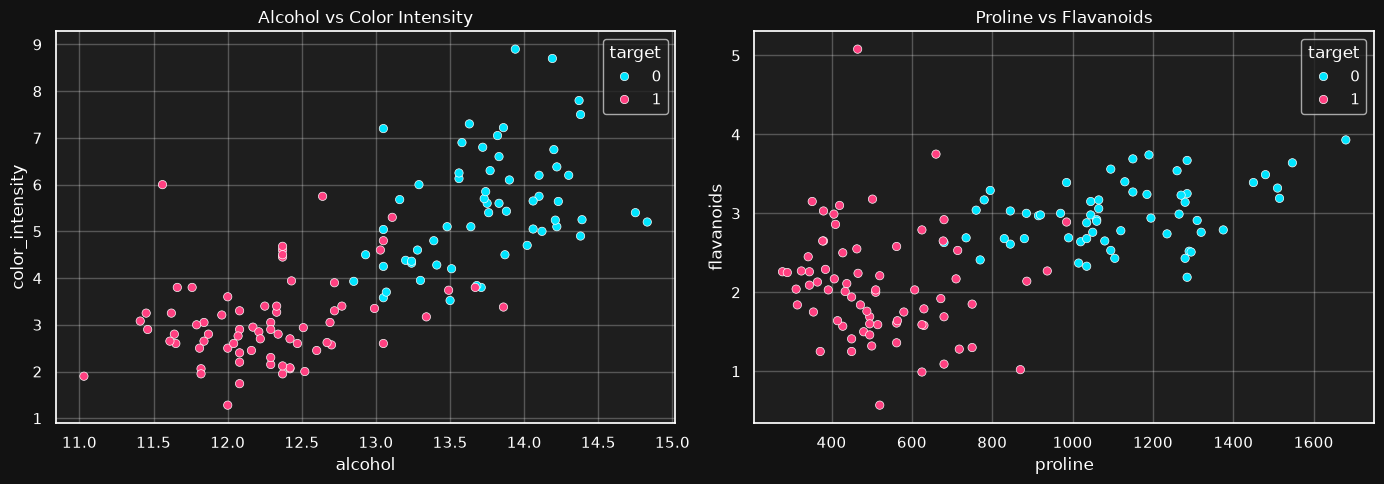

In [ ]:
# Configuramos el estilo de las gráficas
sns.set_theme(
    style="darkgrid",  # "darkgrid" activa la cuadrícula por defecto
    palette="bright",  # Paleta brillante que resalta en fondo oscuro
    rc={
        "axes.facecolor": "#1e1e1e",  # Fondo interno del gráfico
        "figure.facecolor": "#121212",  # Fondo externo de la figura
        "text.color": "white",  # Texto general
        "axes.labelcolor": "white",  # Etiquetas de los ejes
        "xtick.color": "white",  # Marcas del eje X
        "ytick.color": "white",  # Marcas del eje Y
        "grid.color": "#ffffff",  # Color de la cuadrícula en blanco
        "grid.alpha": 0.25,  # Opacidad para que el blanco no sea deslumbrante
        "axes.grid": True,  # Forzar la visualización de la cuadrícula
    },
)

# Creamos una figura con matplotlib que contendrá dos subgráficos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colores_custom = ["#00E5FF", "#FF4081"]
# colores_custom1 = ["#00E5FF", "#FF4081","#40FFA0"]

# Gráfico 1: Alcohol vs Intensidad de Color
sns.scatterplot(
    data=df_binario_0,
    x="alcohol",
    y="color_intensity",
    hue="target",
    palette=colores_custom,
    ax=axes[0],
)
axes[0].set_title("Alcohol vs Color Intensity", color="white")

# Gráfico 2: Proline vs Flavanoids
sns.scatterplot(
    data=df_binario_0,
    x="proline",
    y="flavanoids",
    hue="target",
    palette=colores_custom,
    ax=axes[1],
)
axes[1].set_title("Proline vs Flavanoids", color="white")

"""
# Gráfico 3: Proline vs Flavanoids
sns.scatterplot(
    data=df_wine,
    x="proline",
    y="flavanoids",
    hue="target",
    palette=colores_custom1,
    ax=axes[2],
)
axes[2].set_title("Proline vs Flavanoids, C=3", color="white")
"""

plt.tight_layout()
plt.show()

### 1.4 Separación de DataFrames (2D vs N-D)
A partir de la exploración visual, generaremos un DataFrame únicamente con dos características que consideremos linealmente separables (por ejemplo, 'alcohol' y 'color_intensity') y otro con el vector de características completo.

In [ ]:
# DataFrame 1: Características completas
X_N = df_binario_0.drop('target', axis=1) # Eliminamos la etiqueta target del vector de características


# DataFrame 2: Considerando 2 características
X_2 = df_binario_0[['alcohol', 'color_intensity']]

# Extraemos el Vector de caracteristicas
Y = df_binario_0['target']

In [ ]:
# Conjunto d=130
display(X_N.head(7))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0


In [ ]:
# Conjunto d=2
display(X_2.head(7))

,alcohol,color_intensity
0,14.23,5.64
1,13.20,4.38
2,13.16,5.68
3,14.37,7.80
4,13.24,4.32
5,14.20,6.75
6,14.39,5.25


In [ ]:
# Conjunto de caracteristicas, iguales para ambos conjuntos
display(Y.head(7))

0    0
1    0
2    0
3    0
4    0
5    0
6    0
Name: target, dtype: int64

## Sección 2: Preprocesamiento

En aprendizaje automático, no basta con tener los datos; hay que prepararlos para optimizar el cálculo de los gradientes.

### 2.1 División de conjuntos (Train/Test)
Para cada DataFrame, dividiremos los datos en conjuntos de entrenamiento (70%) y prueba (30%). El conjunto de prueba nos servirá para evaluar la generalización del modelo.

In [ ]:
# División para el dataset de características completas
# test_size=0.3 indica el 30% para prueba. stratify=y garantiza que se mantenga la proporción de clases.
X_N_train, X_N_test, Y_train, Y_test = train_test_split(
    X_N, Y, test_size=0.3, random_state=42, stratify=Y
)

print(f"Muestras de entrenamiento: {X_N_train.shape[0]}")
print(f"Muestras de prueba: {X_N_test.shape[0]}")

Muestras de entrenamiento: 91
Muestras de prueba: 39


### 2.2 Estandarización (StandardScaler)
Aplicaremos `StandardScaler` a las características de ambos conjuntos. Las redes neuronales son muy sensibles a la escala de los datos de entrada. La estandarización centra los datos en una media de 0 y una desviación estándar de 1, calculada como:

$z = \frac{x - \mu}{\sigma}$

**Nota vital:** Ajustamos (`fit`) el escalador *solo* con los datos de entrenamiento para evitar el "Data Leakage" (fuga de información) desde el conjunto de prueba.

In [ ]:
# Normalizamos los datos
scaler_full = StandardScaler()

# Para el dataset completo: fit_transform en train, solo transform en test
# La funcion devuelve un array con los datos normalizados
X_N_train_N = scaler_full.fit_transform(X_N_train)
X_N_test_N = scaler_full.transform(X_N_test)


In [ ]:
# Datos sin normzalizar
display(X_N_train.head(7))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
123,13.05,5.80,2.13,21.5,86.0,2.62,2.65,0.30,2.01,2.60,0.73,3.10,380.0
17,13.83,1.57,2.62,20.0,115.0,2.95,3.40,0.40,1.72,6.60,1.13,2.57,1130.0
95,12.47,1.52,2.20,19.0,162.0,2.50,2.27,0.32,3.28,2.60,1.16,2.63,937.0
61,12.64,1.36,2.02,16.8,100.0,2.02,1.41,0.53,0.62,5.75,0.98,1.59,450.0
30,13.73,1.50,2.70,22.5,101.0,3.00,3.25,0.29,2.38,5.70,1.19,2.71,1285.0
12,13.75,1.73,2.41,16.0,89.0,2.60,2.76,0.29,1.81,5.60,1.15,2.90,1320.0
11,14.12,1.48,2.32,16.8,95.0,2.20,2.43,0.26,1.57,5.00,1.17,2.82,1280.0


In [ ]:
# Datos Normalizados
# Para visualizar los datos debemos convertir el array en un dataframe
X_N_train_N_df = pd.DataFrame(data=X_N_train_N, columns=wine_data.feature_names)
display(X_N_train_N_df.head(7))

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,0.154493,4.333324,-0.699082,0.726726,-0.861750,0.197040,0.295506,-0.289783,0.454156,-0.923726,-1.960961,0.382328,-1.214612
1,1.033173,-0.434645,1.008977,0.293736,0.883575,0.802680,1.400013,0.720572,-0.105899,1.482775,0.450002,-0.818171,0.989634
2,-0.498884,-0.491004,-0.455074,0.005075,3.712206,-0.023193,-0.264111,-0.087712,2.906808,-0.923726,0.630825,-0.682266,0.422408
3,-0.307377,-0.671353,-1.082524,-0.629977,-0.019179,-0.904124,-1.530612,2.034034,-2.230243,0.971393,-0.454109,-3.037962,-1.008882
4,0.920522,-0.513548,1.287843,1.015387,0.041004,0.894444,1.179112,-0.390819,1.168708,0.941312,0.811647,-0.501058,1.445178
5,0.943052,-0.254297,0.276951,-0.860906,-0.681199,0.160334,0.457501,-0.390819,0.067911,0.881150,0.570551,-0.070691,1.548042
6,1.359862,-0.536092,-0.036774,-0.629977,-0.320098,-0.573775,-0.028483,-0.693925,-0.395582,0.520174,0.691099,-0.251898,1.430483


### 2.3 Conversión a Tensores de PyTorch
Para que `PyTorch` pueda realizar el cómputo del grafo y el *backward pass*, los datos deben dejar de ser arreglos de NumPy/Pandas y convertirse a su estructura nativa: los Tensores. Convertiremos los DataFrames a tensores de PyTorch (`torch.FloatTensor`).

In [ ]:
# Convertimos los arreglos escalados a torch.FloatTensor (float32 es el estándar para pesos en redes neuronales)
# Dataset completo
X_N_train_T = torch.tensor(X_N_train_N, dtype=torch.float32)
X_N_test_T = torch.tensor(X_N_test_N, dtype=torch.float32)


# Las etiquetas también deben ser tensores.
# Las pasamos a float32 y redimensionamos de (N,) a (N, 1) usando .unsqueeze(1)
# Esto es esencial porque la salida de la capa nn.Linear tendrá dimensión (N, 1)
Y_train_T = torch.tensor(Y_train.values, dtype=torch.float32).unsqueeze(1)
Y_test_T = torch.tensor(Y_test.values, dtype=torch.float32).unsqueeze(1)

### 2.4 Funciones y operaciones con tensores de PyThorch

#### Inspección de Atributos Básicos
Todo tensor tiene atributos fundamentales que indican sus dimensiones, el tipo de dato que almacena y en qué hardware (CPU o GPU) reside

In [ ]:
# Inspeccionar propiedades del tensor
print("--- ATRIBUTOS DEL TENSOR DE DATOS DE ENTRENAMIENTO ---")
print(f"Forma (shape): {X_N_train_T.shape}")
print(f"Número total de elementos: {X_N_train_T.numel()}")
print(f"Tipo de dato (dtype): {X_N_train_T.dtype}")
print(f"Dispositivo (device): {X_N_train_T.device}")

--- ATRIBUTOS DEL TENSOR DE DATOS DE ENTRENAMIENTO ---
Forma (shape): torch.Size([91, 13])
Número total de elementos: 1183
Tipo de dato (dtype): torch.float32
Dispositivo (device): cpu


In [ ]:
# Inspeccionar propiedades del tensor
print("--- ATRIBUTOS DEL TENSOR DE DATOS DE ENTRENAMIENTO ---")
print(f"Forma (shape): {Y_train_T.shape}")
print(f"Número total de elementos: {Y_train_T.numel()}")
print(f"Tipo de dato (dtype): {Y_train_T.dtype}")
print(f"Dispositivo (device): {Y_train_T.device}")

--- ATRIBUTOS DEL TENSOR DE DATOS DE ENTRENAMIENTO ---
Forma (shape): torch.Size([91, 1])
Número total de elementos: 91
Tipo de dato (dtype): torch.float32
Dispositivo (device): cpu


#### Indexación y Slicing (Rebanado)
Seaborn extraer subconjuntos de datos, como filas específicas, bloques o columnas particulares, usando la misma lógica de indexación que los arreglos de NumPy.

In [ ]:
# Extraer la primera fila completa (todas las columnas)
primera_fila = X_N_train_T[0, :]
print("Primera muestra de entrenamiento:\n", primera_fila)

# Extraer las primeras 3 etiquetas
primeras_etiquetas = Y_train_T[:3]
print("\nPrimeras tres etiquetas:\n", primeras_etiquetas)

Primera muestra de entrenamiento:
 tensor([ 0.1545,  4.3333, -0.6991,  0.7267, -0.8618,  0.1970,  0.2955, -0.2898,
         0.4542, -0.9237, -1.9610,  0.3823, -1.2146])

Primeras tres etiquetas:
 tensor([[1.],
        [0.],
        [1.]])


#### Modificación de Forma (Squeeze, Unsqueeze y View)
Estas operaciones cambian la estructura geométrica del tensor sin alterar los datos subyacentes en memoria. squeeze() elimina las dimensiones de tamaño 1, revirtiendo el efecto del .unsqueeze(1) original. view() reorganiza la matriz completamente.

In [ ]:
# Revertir el unsqueeze: de (N, 1) a (N,)
etiquetas_planas = Y_train_T.squeeze()
print(f"Forma de Y_train original: {Y_train_T.shape}\n")
print(f"{Y_train_T[:5]}")

print("="*100)
print(f"Forma de Y_train tras squeeze(): {etiquetas_planas.shape}")
print(f"Forma de Y_train tras squeeze(): {etiquetas_planas[0:5]}")

Forma de Y_train original: torch.Size([91, 1])

tensor([[1.],
        [0.],
        [1.],
        [1.],
        [0.]])
Forma de Y_train tras squeeze(): torch.Size([91])
Forma de Y_train tras squeeze(): tensor([1., 0., 1., 1., 0.])


#### Operaciones Matemáticas por Elemento (Element-wise)
Se pueden aplicar cálculos aritméticos directamente a todo el tensor, aplicando la operación valor por valor.

In [ ]:
# Extraemos una pequeña muestra para visualizar fácilmente
muestra = X_N_train_T[:2, 2:7]
print("Muestra original:\n", muestra)

# Suma y multiplicación escalar
muestra_modificada = (muestra + 10) * 2
print("\nMuestra tras sumar 10 y multiplicar por 2:\n", muestra_modificada)

Muestra original:
 tensor([[-0.6991,  0.7267, -0.8618,  0.1970,  0.2955],
        [ 1.0090,  0.2937,  0.8836,  0.8027,  1.4000]])

Muestra tras sumar 10 y multiplicar por 2:
 tensor([[18.6018, 21.4535, 18.2765, 20.3941, 20.5910],
        [22.0180, 20.5875, 21.7672, 21.6054, 22.8000]])


#### Agregaciones Estadísticas por Eje
Calculan métricas reduciendo las dimensiones del tensor. Al usar dim=0, la operación se aplica a través de las filas (calculando el resultado por columna). Al usar .item(), se extrae el valor numérico puro de un tensor que contiene un solo elemento.

In [ ]:
# Promedio de cada característica (reducción por columnas usando dim=0)
media_columnas = X_N_train_T.mean(dim=0)
print("Media de las características:\n", media_columnas)

# Desviación estándar
std_columnas = X_N_train_T.std(dim=0)
print("\nDesviación estándar por columna:\n", std_columnas)

# Valor máximo absoluto de toda la matriz
max_val = X_N_train_T.max()
print(f"\nValor máximo global (como número puro): {max_val.item():.4f}")

Media de las características:
 tensor([ 0.0000e+00, -5.2400e-09,  2.2925e-09, -3.9300e-09,  6.5500e-09,
         0.0000e+00,  0.0000e+00, -5.2400e-09, -2.6200e-09,  5.2400e-09,
        -2.6200e-09,  5.2400e-09,  5.2400e-09])

Desviación estándar por columna:
 tensor([1.0055, 1.0055, 1.0055, 1.0055, 1.0055, 1.0055, 1.0055, 1.0055, 1.0055,
        1.0055, 1.0055, 1.0055, 1.0055])

Valor máximo global (como número puro): 4.3333


## Sección 3: Construcción del Perceptrón

En el contexto del aprendizaje automático, un perceptrón simple es equivalente a un modelo de **Regresión Logística**. Matemáticamente, aplica una transformación afín sobre las características de entrada seguida de una función de activación no lineal:

$z = XW^T + b$

Donde $X$ es la matriz de entrada, $W$ son los pesos (parámetros a aprender) y $b$ es el sesgo (bias). La salida del modelo son los *logits* ($z$), que luego se mapearán a probabilidades usando una función Sigmoide $\sigma(z)$.

### 3.1 Definición de la Arquitectura
Definiremos un modelo usando una sola capa lineal: `nn.Linear(in_features, 1)`. Es una excelente práctica heredar de `nn.Module` para entender la anatomía de una red en PyTorch, que consta siempre de un constructor (`__init__`) y una función de propagación hacia adelante (`forward`).

In [ ]:
# Definición de la clase del modelo
class PerceptronSimple(nn.Module):
    def __init__(self, in_features):
        """
        Constructor del modelo.
        Parámetros:
        - in_features (int): Cantidad de características de entrada.
        """
        super(PerceptronSimple, self).__init__()
        # nn.Linear inicializa aleatoriamente los pesos (W) y el sesgo (b)
        self.capa_lineal = nn.Linear(in_features, 1)

    def __call__(self, x):
        """
        Intercepción de __call__.
        En POO, al usar modelo(X), Python invoca este método.
        Llamamos a super().__call__(x) para que la clase padre (nn.Module)
        haga su trabajo interno y sea ella quien invoque a nuestro forward(x).
        """
        # Iniciando propagación en nn.Module
        return super().__call__(x)

    def forward(self, x):
        """
        Implementación polimórfica: nn.Module espera que las clases hijas
        definan este método con las operaciones matemáticas específicas.
        """
        z = self.capa_lineal(x)
        return torch.sigmoid(z)

# Instanciación del Modelo
d = X_N_train.shape[1]
modelo = PerceptronSimple(in_features=d) # d=13

# Configuración de la Función de Pérdida Binary Cross Entropy.
f_perdida = nn.BCELoss()

# Instanciación del optimizador
# Adam ajusta la tasa de aprendizaje dinámicamente usando momentos de primer y segundo orden.
# El parámetro 'lr' (Learning Rate) dicta el tamaño del paso en la dirección opuesta al gradiente.
optimizador = optim.Adam(modelo.parameters(), lr=0.05)

---
## Sección 4: Ciclo de Entrenamiento

El entrenamiento de una red neuronal es un problema de optimización. Nuestro objetivo es minimizar la función de pérdida iterando sobre nuestros datos múltiples veces (épocas).

En cada época, el flujo computacional es el siguiente:
1. **Forward pass**: Calculamos $z$ pasando las entradas por el modelo.
2. **Cálculo de pérdida**: Comparamos $z$ contra los valores reales $y$.
3. **Limpieza de gradientes (`zero_grad`)**: PyTorch acumula gradientes por defecto. Si no los borramos, ¡los gradientes de la época actual se sumarán a los de la anterior, arruinando la actualización matemática!
4. **Backward pass (`backward`)**: Se aplica la regla de la cadena (Backpropagation) para calcular derivadas parciales $\nabla L$.
5. **Actualización (`step`)**: El optimizador ajusta los pesos en dirección negativa al gradiente.

Programaremos el ciclo de entrenamiento por épocas para ambos conjuntos de datos.

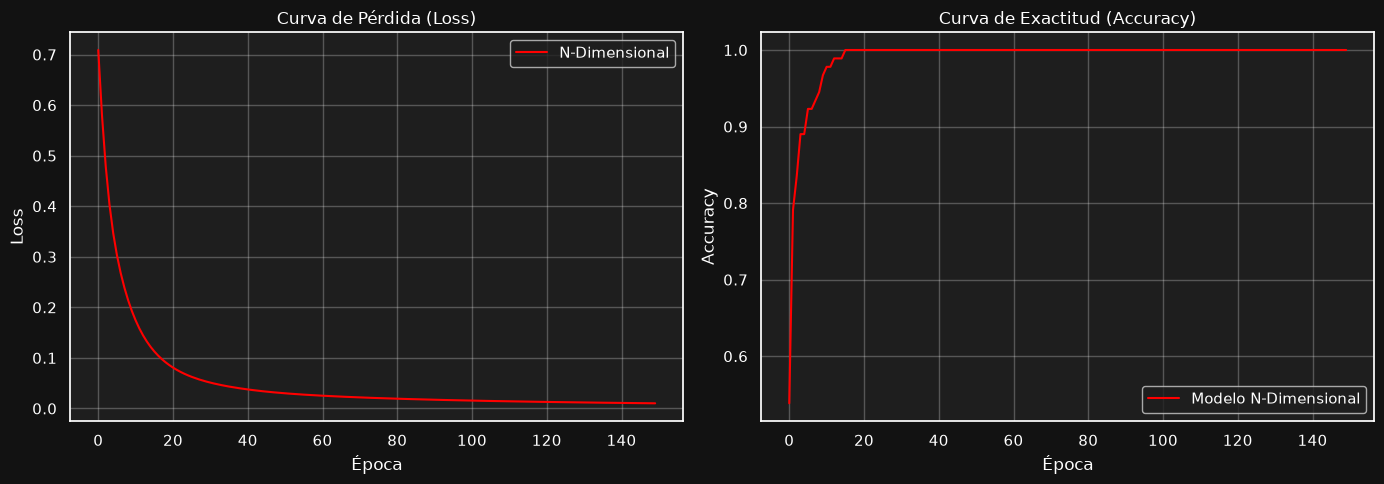

In [ ]:
def entrenar_modelo(modelo, optimizador, f_perdida, X_train, y_train, epocas=100):
    historial_loss = []
    historial_acc = []

    for epoca in range(epocas):
        # 1. Modo entrenamiento
        modelo.train()

        # 2. Forward pass (Paso hacia adelante)
        salidas = modelo(X_train)

        # 3. Cálculo de pérdida
        loss = f_perdida(salidas, y_train)

        # 4. Limpieza de gradientes (zero_grad)
        optimizador.zero_grad()

        # 5. Backward pass (Paso hacia atrás)
        loss.backward()

        # 6. Actualización de pesos (step)
        optimizador.step()

        # Cálculo de Exactitud (Accuracy)

        # Umbralización: Si p >= 0.5, clase 1. Si no, clase 0.
        predicciones = (salidas >= 0.5).float()

        # Comparamos predicciones contra los valores reales
        correctas = (predicciones == y_train).sum().item()
        exactitud = correctas / len(y_train)

        # Almacenamiento de valores (Loss y Accuracy) en cada época
        historial_loss.append(loss.item())
        historial_acc.append(exactitud)

    return historial_loss, historial_acc

# Entrenamosel modelo
epocas = 150
loss, acc = entrenar_modelo(modelo, optimizador, f_perdida, X_N_train_T, Y_train_T, epocas=epocas)

# Graficamos los resultados
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Pérdida
axes[0].plot(loss, label='N-Dimensional', color='red')
axes[0].set_title('Curva de Pérdida (Loss)')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Gráfico de Exactitud
axes[1].plot(acc, label='Modelo N-Dimensional', color='red')
axes[1].set_title('Curva de Exactitud (Accuracy)')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

### 4.1 Explicación del Ciclo de Entrenamiento en PyTorch

#### 1. Modo Entrenamiento (`modelo.train()`)
No involucra una ecuación directa, pero habilita las banderas internas en el grafo computacional para que operaciones como *Dropout* o *Batch Normalization* funcionen en modo estocástico. A nivel de tensores, asegura que las matrices de pesos $W$ y el sesgo $b$ estén listos para acumular gradientes ($\text{requires\_grad} = \text{True}$).

---

#### 2. Forward Pass (`salidas = modelo(X_train)`)
El modelo aplica una transformación lineal seguida de una activación no lineal. Para una matriz de entrada $X$, pesos $W$ y sesgo $b$, el producto punto genera los *logits* ($z$):

$$z = XW^T + b$$

Inmediatamente, la función Sigmoide comprime los valores al rango $[0, 1]$ para convertirlos en probabilidades ($A$):

$$A = \sigma(z) = \frac{1}{1 + e^{-z}}$$

---

#### 3. Cálculo de Pérdida (`loss = f_perdida(salidas, y)`)
La Entropía Cruzada Binaria (BCELoss) cuantifica el error promedio entre la probabilidad predicha $A$ y la etiqueta real $y \in \{0,1\}$ sobre $N$ muestras. Penaliza logarítmicamente las predicciones seguras pero incorrectas:

$$L = -\frac{1}{N}\sum_{i=1}^{N}\left[y_i \log(A_i) + (1-y_i)\log(1-A_i)\right]$$

---

#### 4. Limpieza de Gradientes (`optimizador.zero_grad()`)
PyTorch acumula los gradientes por defecto en cada iteración. Para evitar que las derivadas de la época actual se sumen a las de la época anterior, se fuerzan a cero las matrices de derivadas parciales almacenadas en la memoria del optimizador:

$$\frac{\partial L}{\partial W} = 0, \quad \frac{\partial L}{\partial b} = 0$$

---

#### 5. Backward Pass (`loss.backward()`)
El motor *Autograd* aplica la regla de la cadena del cálculo diferencial (Retropropagación) desde la pérdida $L$ hasta los pesos $W$ viajando por el grafo computacional:

$$\frac{\partial L}{\partial W} = \frac{\partial L}{\partial A} \cdot \frac{\partial A}{\partial z} \cdot \frac{\partial z}{\partial W}$$

Al derivar la función Sigmoide combinada con la BCELoss, el gradiente exacto se simplifica a la diferencia entre la predicción y el valor real, multiplicada por las entradas originales:

$$\frac{\partial L}{\partial W} = \frac{1}{N} (A - y) X^T$$

---

#### 6. Actualización de Pesos (`optimizador.step()`)
Se aplica el algoritmo de optimización (por ejemplo, Descenso del Gradiente estándar) para ajustar los pesos en dirección contraria al gradiente. Si $\alpha$ es la tasa de aprendizaje (*learning rate*), los nuevos pesos $W_{t+1}$ se calculan como:

$$W_{t+1} = W_t - \alpha \frac{\partial L}{\partial W}$$

---
## Sección 5: Evaluación y Comparación de Modelos

El verdadero rendimiento de un modelo de Machine Learning se mide en datos que nunca ha visto. Realizaremos el proceso de evaluación para ambos modelos entrenados.

**Consideraciones críticas en inferencia:**
* Usaremos `torch.no_grad()`. Esto apaga el motor de Autograd de PyTorch. Si lo olvidamos en modelos grandes, agotaremos la memoria RAM debido a que PyTorch guardará el grafo computacional innecesariamente.

In [ ]:
# Evaluación del Modelo y obtención de predicciones
y_real = Y_test_T.squeeze().numpy()

## Inferencia del modelo
modelo.eval()
with torch.no_grad():
    salidas = modelo(X_N_test_T)

# print(f"{(salidas >=5 )}")
y_pred = (salidas >= 0.5).float().squeeze().numpy()

# Calcular Métricas de Evaluación
exactitud = accuracy_score(y_real, y_pred)
precision = precision_score(y_real, y_pred)
sensibilidad = recall_score(y_real, y_pred)
f1 = f1_score(y_real, y_pred)


# Imprimir reporte en consola
print("=" * 54)
print("=====  REPORTE DE MÉTRICAS (Conjunto de Prueba)  =====")
print("=" * 54)
print(f"Exactitud (Accuracy):  {exactitud:.4f}")
print(f"Precisión (Precision): {precision:.4f}")
print(f"Sensibilidad (Recall): {sensibilidad:.4f}")
print(f"F1-Score:              {f1:.4f}")


print("=" * 54)
print(classification_report(y_real, y_pred))

=====  REPORTE DE MÉTRICAS (Conjunto de Prueba)  =====
Exactitud (Accuracy):  0.9487
Precisión (Precision): 1.0000
Sensibilidad (Recall): 0.9048
F1-Score:              0.9500
              precision    recall  f1-score   support

         0.0       0.90      1.00      0.95        18
         1.0       1.00      0.90      0.95        21

    accuracy                           0.95        39
   macro avg       0.95      0.95      0.95        39
weighted avg       0.95      0.95      0.95        39



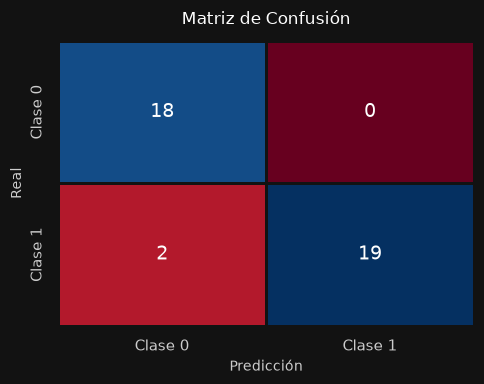

In [ ]:
# Calcular matriz
cm = confusion_matrix(y_real, y_pred)

# Estilo oscuro minimalista
sns.set_theme(
    style="dark",
    rc={
        "axes.facecolor": "#1e1e1e",
        "figure.facecolor": "#121212",
        "text.color": "white",
        "axes.labelcolor": "#cccccc",
        "xtick.color": "#cccccc",
        "ytick.color": "#cccccc",
    },
)

# Gráfico simple
plt.figure(figsize=(5, 4))
ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="RdBu",  # Paleta de color: "crest", "mako", "rocket", "vlag", "magma", "inferno", "plasma", "viridis", "cividis", etc
    cbar=False,  # Ocultamos la barra de color para simplificar
    linewidths=2,
    linecolor="#121212",  # Separa las celdas con el color de fondo
    annot_kws={"size": 14},
)

# Etiquetas directas y limpias
ax.set_title("Matriz de Confusión", pad=12, fontsize=12)
ax.set_xlabel("Predicción", fontsize=10)
ax.set_ylabel("Real", fontsize=10)
ax.set_xticklabels(["Clase 0", "Clase 1"])
ax.set_yticklabels(["Clase 0", "Clase 1"])

plt.tight_layout()
plt.show()

### 5.1 Análisis Geométrico: Extracción de Pesos y Frontera de Decisión

Un Perceptrón Simple busca el hiperplano (en 2D, una línea recta) que mejor separa las clases. Matemáticamente, la frontera de decisión se encuentra donde la probabilidad es exactamente $0.5$, es decir, donde los logits $z = 0$.

Para dos dimensiones ($x_1, x_2$), la ecuación es:
$w_1x_1 + w_2x_2 + b = 0$

Si despejamos $x_2$ (que representaremos en el eje Y de nuestra gráfica), obtenemos la ecuación de la recta de la forma $y = mx + c$:
$x_2 = -\frac{w_1}{w_2}x_1 - \frac{b}{w_2}$

**Problema común en PyTorch:**
Los pesos (`weight`) y el sesgo (`bias`) dentro de la capa lineal son Tensores que forman parte del grafo computacional (tienen `requires_grad=True`). Si intentamos convertirlos directamente a arreglos de NumPy usando `.numpy()`, PyTorch arrojará un error. Primero debemos "desengancharlos" del motor de Autograd usando el método `.detach()`.

In [ ]:
# Extraemos W para el modelo completo (forma: 1 x 13)
W = modelo.capa_lineal.weight.detach().numpy()[0]
b = modelo.capa_lineal.bias.detach().numpy()[0]

print("="*50)
print("Parámetros del Modelo N-Dimensional:")
print(f"W_d: {W}")
print(f"b: {b:.4f}")
print("="*50)
# Necesitamos encontrar qué índices corresponden a 'alcohol' y 'color_intensity' en nuestro DataFrame original
idx_alcohol = X_N.columns.get_loc('alcohol')
idx_color = X_N.columns.get_loc('color_intensity')

idx_proline = X_N.columns.get_loc('proline')
idx_flavanoids = X_N.columns.get_loc('flavanoids')


w1_0 = W[idx_alcohol]
w2_0 = W[idx_color]

w1_1 = W[idx_proline]
w2_1 = W[idx_flavanoids]

print("Parámetros proyectados del Modelo N-Dimensional:")
print(f"w_alcohol: {w1_0:.4f}")
print(f"w_color: {w2_0:.4f}")
print(f"b: {b:.4f}")

Parámetros del Modelo N-Dimensional:
W_d: [-1.8679576  -0.66595864 -1.5190507   2.3766842  -0.93315774 -0.4398001
 -1.1171519  -0.29578364  1.2470801  -1.431725    0.35013875 -0.9717263
 -1.7139454 ]
b: 0.3219
Parámetros proyectados del Modelo N-Dimensional:
w_alcohol: -1.8680
w_color: -1.4317
b: 0.3219


### 5.3 Graficando la Frontera de Decisión

Ahora graficaremos los datos (usando el conjunto de prueba escalado) y sobrepondremos la recta generada por nuestros pesos.

**¿Cómo graficamos la recta del modelo Multidimensional en solo 2D?**
Al tener 13 dimensiones, el modelo generó un hiperplano en 13D:
$w_1x_1 + w_2x_2 + ... + w_{13}x_{13} + b = 0$

Para proyectar esto en un plano 2D (solo considerando Alcohol y Color), debemos asumir valores fijos para el resto de las variables. **¡Aquí radica la magia de haber usado `StandardScaler`!** Como estandarizamos los datos, la media de todas las características es $0$. Por lo tanto, si evaluamos la recta en el valor promedio de las demás variables ($x_i = 0$), sus términos se anulan, permitiéndonos usar la misma fórmula matemática:
$x_{color} = -\frac{w_{alcohol}}{w_{color}}x_{alcohol} - \frac{b}{w_{color}}$

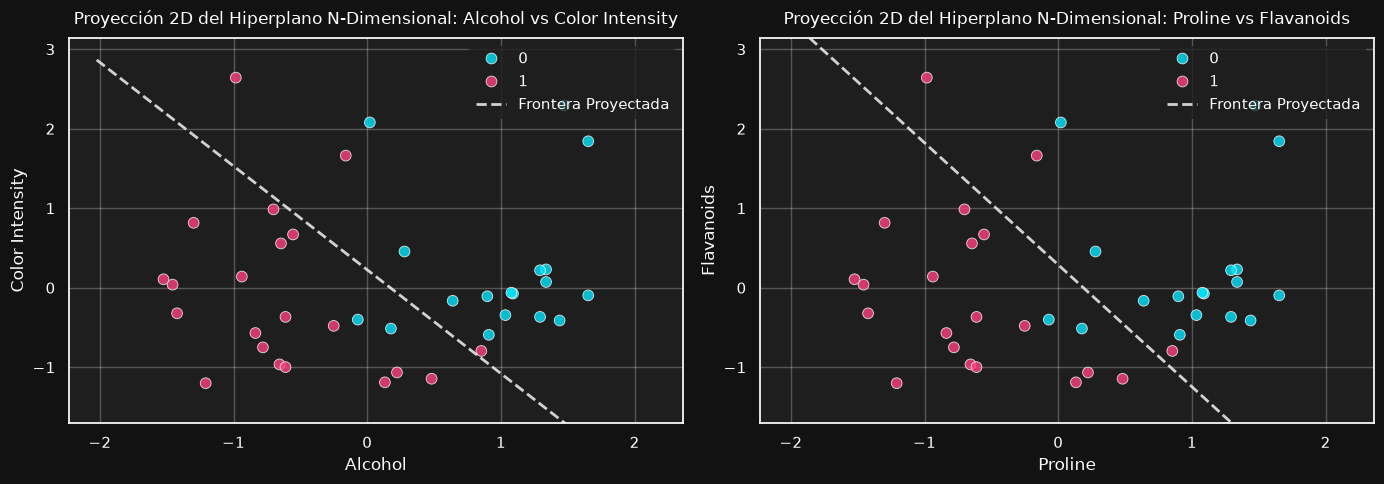

In [ ]:
# Configuramos el estilo
sns.set_theme(
    style="darkgrid",  # "darkgrid" activa la cuadrícula por defecto
    palette="bright",
    rc={
        "axes.facecolor": "#1e1e1e",  # Fondo interno del gráfico
        "figure.facecolor": "#121212",  # Fondo externo de la figura
        "text.color": "white",  # Texto general
        "axes.labelcolor": "white",  # Etiquetas de los ejes
        "xtick.color": "white",  # Marcas del eje X
        "ytick.color": "white",  # Marcas del eje Y
        "grid.color": "#ffffff",  # Color de la cuadrícula
        "grid.alpha": 0.25,  # Opacidad
        "axes.grid": True,  # Forzar la visualización de la cuadrícula
    },
)

# Preparamos una figura con dos subgráficos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Generamos un rango de valores para el eje X
x_vals = np.linspace(X_N_test_N[:, 0].min() - 0.5, X_N_test_N[:, 0].max() + 0.5, 100)

# ==========================================
# GRÁFICO 1: Alcohol vs Color Intensity
# ==========================================
y_vals_0 = -(w1_0 / w2_0) * x_vals - (b / w2_0)

# Puntos reales usando Seaborn
sns.scatterplot(
    x=X_N_test_N[:, 0],
    y=X_N_test_N[:, 1],
    hue=Y_test,
    palette=colores_custom,
    alpha=0.8,
    s=60,  # Tamaño de punto
    ax=axes[0],
)

# Frontera de decisión proyectada
axes[0].plot(
    x_vals,
    y_vals_0,
    color="#FFFFFFCC",
    linestyle="--",
    linewidth=2,
    label="Frontera Proyectada",
)

axes[0].set_title(
    "Proyección 2D del Hiperplano N-Dimensional: Alcohol vs Color Intensity",
    color="white",
    fontsize=12,
    pad=10,
)
axes[0].set_xlabel("Alcohol")
axes[0].set_ylabel("Color Intensity")
axes[0].set_ylim(X_N_test_N[:, 1].min() - 0.5, X_N_test_N[:, 1].max() + 0.5)
axes[0].legend(loc ="upper right", facecolor="#1e1e1e", edgecolor="none", labelcolor="white")

# ==========================================
# GRÁFICO 2: Proline vs Flavanoids
# ==========================================
# Cálculo de la segunda frontera proyectada
y_vals_1 = -(w1_1 / w2_1) * x_vals - (b / w2_1)

# Puntos reales usando Seaborn
sns.scatterplot(
    x=X_N_test_N[:, 0],
    y=X_N_test_N[:, 1],
    hue=Y_test,
    palette=colores_custom,
    alpha=0.8,
    s=60,
    ax=axes[1],
)

# Frontera de decisión proyectada
axes[1].plot(
    x_vals,
    y_vals_1,
    color="#FFFFFFCC",
    linestyle="--",
    linewidth=2,
    label="Frontera Proyectada",
)

axes[1].set_title(
    "Proyección 2D del Hiperplano N-Dimensional: Proline vs Flavanoids",
    color="white",
    fontsize=12,
    pad=10,
)
axes[1].set_xlabel("Proline")
axes[1].set_ylabel("Flavanoids")
axes[1].set_ylim(X_N_test_N[:, 1].min() - 0.5, X_N_test_N[:, 1].max() + 0.5)
axes[1].legend(loc ="upper right",facecolor="#1e1e1e", edgecolor="none", labelcolor="white")

plt.tight_layout()
plt.show()